In [1]:
import os
import multiprocessing as mp

# One numerical thread per worker; run this cell before importing climlab/NumPy.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
             "NUMEXPR_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"

from pathlib import Path
from datetime import datetime, timedelta
from contextlib import ExitStack
import json

import numpy as np
import netCDF4 as nc
import xarray as xr
import matplotlib.pyplot as plt
import climlab
from climlab.solar.insolation import daily_insolation_factors

In [2]:
DATA_DIR = Path("/data92/b11209013/ERA5_GRIB/Data/tropical_-10_10")
OUTPUT = Path("/data92/b11209013/RRTMG_total_heating_2006_2017_-5_5.nc")
LATITUDE_RANGE = (-5., 5.)
BATCH_SIZE = 256
N_WORKERS = 16

INPUT_FILES = {
    "T": ("T_no_rm3harm.nc", "T"),
    "q": ("Q_no_rm3harm.nc", "Q"),
}

SURFACE_PRESSURE = 1013.25  # hPa
ALBEDO = 0.06
EMISSIVITY = 1.
SOLAR_CONSTANT = 1361.
UPPER_PRESSURE = np.array([1., 5., 10., 20., 50.])
UPPER_TEMPERATURE = np.array([270., 250., 230., 215., 205.])
UPPER_HUMIDITY = 3e-6
ABSORBERS = {
    "CO2": 400e-6, "CH4": 1800e-9, "N2O": 320e-9, "O2": .21,
    "O3": 0., "CFC11": 0., "CFC12": 0., "CFC22": 0., "CCL4": 0.,
}

In [3]:
def calculate_heating(T, q, pressure, latitude, date):
    """Return total clear-sky LW and SW heating for the supplied T/q, in K/day."""
    valid = np.all(
        np.isfinite(T) & np.isfinite(q)
        & (T >= 150.) & (T <= 350.) & (q >= 0.) & (q < .1), axis=1,
    )
    LW, SW = np.full(T.shape, np.nan), np.full(T.shape, np.nan)
    if not valid.any():
        return LW, SW

    levels = np.concatenate((UPPER_PRESSURE, pressure))
    bounds = np.r_[0., (levels[:-1] + levels[1:]) / 2., SURFACE_PRESSURE]
    if (np.any(np.diff(levels) <= 0) or np.any(levels <= bounds[:-1])
            or np.any(levels >= bounds[1:])):
        raise ValueError("Pressure centers must increase and lie inside their layer boundaries.")
    axis = climlab.domain.Axis(axis_type="lev", points=levels, bounds=bounds)
    ncol, nupper = int(valid.sum()), len(UPPER_PRESSURE)
    # The model's horizontal axis is a batch index; solar geometry uses real latitudes.
    state = climlab.column_state(lev=axis, num_lat=ncol)
    temperature = state["Tatm"].reshape(ncol, -1)
    temperature[:, :nupper] = UPPER_TEMPERATURE
    temperature[:, nupper:] = T[valid]
    humidity = np.zeros_like(state["Tatm"])
    humidity_columns = humidity.reshape(ncol, -1)
    humidity_columns[:, :nupper] = UPPER_HUMIDITY
    humidity_columns[:, nupper:] = q[valid]
    # Lowest-level air temperature is the surface radiative-temperature proxy.
    state["Ts"][:] = T[valid, -1].reshape(state["Ts"].shape)
    coszen, factor = daily_insolation_factors(
        latitude[valid], date.timetuple().tm_yday, weighting="insolation",
    )
    radiation = climlab.radiation.RRTMG(
        state=state, specific_humidity=humidity, absorber_vmr=ABSORBERS.copy(),
        icld=0, iaer=0, cldfrac=0., clwp=0., ciwp=0.,
        albedo=ALBEDO, emissivity=EMISSIVITY, S0=SOLAR_CONSTANT,
        coszen=np.asarray(coszen).reshape(state["Ts"].shape),
        irradiance_factor=np.asarray(factor).reshape(state["Ts"].shape), dyofyr=0,
    )
    radiation.compute_diagnostics(num_iter=1)
    lw = np.asarray(radiation.TdotLW).reshape(ncol, -1)[:, nupper:]
    sw = np.asarray(radiation.TdotSW).reshape(ncol, -1)[:, nupper:]
    if not (np.isfinite(lw).all() and np.isfinite(sw).all()):
        raise FloatingPointError("Non-finite RRTMG heating rate.")
    np.testing.assert_allclose(
        np.asarray(radiation.SW_flux_down).reshape(ncol, -1)[:, 0],
        SOLAR_CONSTANT * np.asarray(coszen).reshape(-1) * np.asarray(factor).reshape(-1),
        rtol=1e-4, atol=1e-3,
    )
    LW[valid], SW[valid] = lw, sw
    return LW, SW


In [4]:
with ExitStack() as stack:
    # Linux fork lets workers use notebook functions without a separate module.
    # Start workers before opening NetCDF files; only the parent accesses files.
    pool = stack.enter_context(mp.get_context("fork").Pool(processes=N_WORKERS))
    inputs = {
        key: stack.enter_context(nc.Dataset(DATA_DIR / filename))
        for key, (filename, _) in INPUT_FILES.items()
    }
    grid = inputs["T"]
    for key, source in inputs.items():
        for coordinate in ("time", "plev", "lat", "lon"):
            np.testing.assert_array_equal(source[coordinate][:], grid[coordinate][:])
        variable = source[INPUT_FILES[key][1]]
        assert variable.dimensions == ("time", "plev", "lat", "lon")
        assert variable.units == ("K" if key.startswith("T") else "kg kg**-1")
    assert grid["plev"].units == "Pa"
    assert grid["time"].units == "day as %Y%m%d.%f"

    lat_index = np.flatnonzero(
        (grid["lat"][:] >= LATITUDE_RANGE[0]) & (grid["lat"][:] <= LATITUDE_RANGE[1])
    )
    if not lat_index.size:
        raise ValueError("No latitude points within LATITUDE_RANGE.")
    pressure = np.asarray(grid["plev"][:], dtype=float) / 100.
    latitude = np.asarray(grid["lat"][lat_index], dtype=float)
    longitude = np.asarray(grid["lon"][:], dtype=float)
    time_values = np.asarray(grid["time"][:], dtype=float)
    dates = [datetime.strptime(str(int(t)), "%Y%m%d") + timedelta(days=float(t-int(t)))
             for t in time_values]
    nt, nz, ny, nx = len(dates), len(pressure), len(latitude), len(longitude)
    column_latitude = np.repeat(latitude, nx)
    batches = [slice(first, min(first+BATCH_SIZE, ny*nx))
               for first in range(0, ny*nx, BATCH_SIZE)]

    OUTPUT.parent.mkdir(parents=True, exist_ok=True)
    output = stack.enter_context(nc.Dataset(OUTPUT, "w"))
    output.status = "incomplete"
    output.Conventions = "CF-1.8"
    output.climlab_version = climlab.__version__
    output.definition = "Direct RRTMG TdotLW and TdotSW for absolute T and specific humidity; no background or mean subtraction"
    output.assumptions = (
        "Clear sky; zero ozone and aerosols; prescribed upper atmosphere and gases; "
        "uniform surface pressure/albedo/emissivity; surface T approximated by lowest-level air T; "
        "effective daily-mean solar geometry. Not isolated cloud heating."
    )
    output.configuration = json.dumps({
        "inputs": {key: str(DATA_DIR / filename) for key, (filename, _) in INPUT_FILES.items()},
        "workers": N_WORKERS, "batch_size": BATCH_SIZE,
        "latitude_range": LATITUDE_RANGE, "surface_pressure_hpa": SURFACE_PRESSURE,
        "albedo": ALBEDO, "emissivity": EMISSIVITY, "solar_constant": SOLAR_CONSTANT,
        "upper_pressure_hpa": UPPER_PRESSURE.tolist(),
        "upper_temperature_K": UPPER_TEMPERATURE.tolist(),
        "upper_humidity": UPPER_HUMIDITY, "absorber_vmr": ABSORBERS,
    })
    for name, size in (("time", nt), ("plev", nz), ("lat", ny), ("lon", nx)):
        output.createDimension(name, size)
    time_coordinate = output.createVariable("time", "f8", ("time",))
    time_coordinate.units = "days since 1970-01-01 00:00:00"
    time_coordinate.calendar = "proleptic_gregorian"
    time_coordinate[:] = nc.date2num(dates, time_coordinate.units, time_coordinate.calendar)
    for name, values, units in (("plev", pressure, "hPa"), ("lat", latitude, "degrees_north"),
                                ("lon", longitude, "degrees_east")):
        coordinate = output.createVariable(name, "f8", (name,))
        coordinate[:] = values
        coordinate.units = units
    output["plev"].positive = "down"
    for band in ("LW", "SW"):
        variable = output.createVariable(
            f"Q{band}", "f4", ("time", "plev", "lat", "lon"),
            zlib=True, complevel=1, chunksizes=(1, nz, ny, min(120, nx)), fill_value=np.nan,
        )
        variable.units = "K day-1"
        variable.positive = "warming"
        variable.long_name = f"Total clear-sky {band} radiative heating rate"

    for it, date in enumerate(dates):
        profiles = {
            key: np.ma.asarray(source[INPUT_FILES[key][1]][it, :, lat_index, :], dtype=float)
                .filled(np.nan).transpose(1, 2, 0).reshape(ny*nx, nz)
            for key, source in inputs.items()
        }
        LW = np.full((ny*nx, nz), np.nan, dtype=np.float32)
        SW = np.full_like(LW, np.nan)
        results = pool.starmap(
            calculate_heating,
            ((profiles["T"][batch], profiles["q"][batch],
              pressure, column_latitude[batch], date) for batch in batches),
            chunksize=1,
        )
        # starmap returns results in input order, preserving latitude/longitude.
        for batch, (lw, sw) in zip(batches, results):
            LW[batch], SW[batch] = lw, sw
        output["QLW"][it] = LW.reshape(ny, nx, nz).transpose(2, 0, 1)
        output["QSW"][it] = SW.reshape(ny, nx, nz).transpose(2, 0, 1)
        output.completed_times = it+1
        output.sync()
        if (it+1) % 100 == 0 or it+1 == nt:
            print(f"{it+1}/{nt}: {date:%Y-%m-%d}")
    output.status = "complete"

print(f"Saved {OUTPUT}")

100/4383: 2006-04-10
200/4383: 2006-07-19
300/4383: 2006-10-27
400/4383: 2007-02-04
500/4383: 2007-05-15
600/4383: 2007-08-23
700/4383: 2007-12-01
800/4383: 2008-03-10
900/4383: 2008-06-18
1000/4383: 2008-09-26
1100/4383: 2009-01-04
1200/4383: 2009-04-14
1300/4383: 2009-07-23
1400/4383: 2009-10-31
1500/4383: 2010-02-08
1600/4383: 2010-05-19
1700/4383: 2010-08-27
1800/4383: 2010-12-05
1900/4383: 2011-03-15
2000/4383: 2011-06-23
2100/4383: 2011-10-01
2200/4383: 2012-01-09
2300/4383: 2012-04-18
2400/4383: 2012-07-27
2500/4383: 2012-11-04
2600/4383: 2013-02-12
2700/4383: 2013-05-23
2800/4383: 2013-08-31
2900/4383: 2013-12-09
3000/4383: 2014-03-19
3100/4383: 2014-06-27
3200/4383: 2014-10-05
3300/4383: 2015-01-13
3400/4383: 2015-04-23
3500/4383: 2015-08-01
3600/4383: 2015-11-09
3700/4383: 2016-02-17
3800/4383: 2016-05-27
3900/4383: 2016-09-04
4000/4383: 2016-12-13
4100/4383: 2017-03-23
4200/4383: 2017-07-01
4300/4383: 2017-10-09
4383/4383: 2017-12-31
Saved /data92/b11209013/RRTMG_total_heati

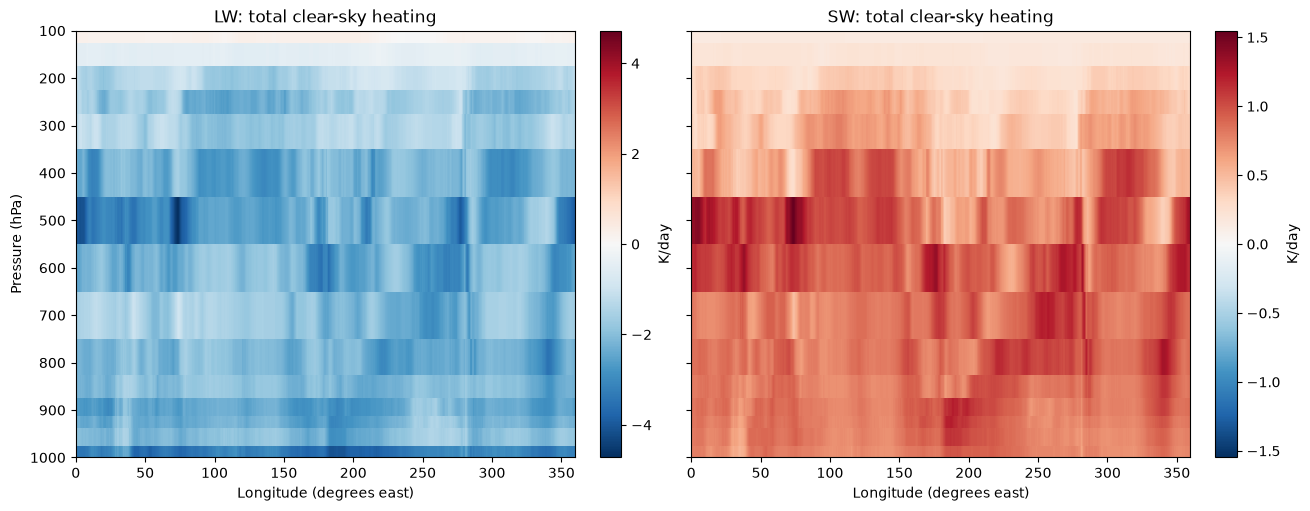

In [5]:
with xr.open_dataset(OUTPUT) as result:
    if result.attrs.get("status") != "complete":
        raise RuntimeError("The output calculation is incomplete.")
    sample = result[["QLW", "QSW"]].isel(time=0).mean("lat").load()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True, constrained_layout=True)
for ax, band in zip(axes, ("LW", "SW")):
    field = sample[f"Q{band}"]
    limit = float(np.abs(field).max(skipna=True))
    limit = max(limit, 1e-6) if np.isfinite(limit) else 1.
    shading = ax.pcolormesh(sample.lon, sample.plev, field, cmap="RdBu_r",
                            vmin=-limit, vmax=limit, shading="auto")
    ax.set_title(f"{band}: total clear-sky heating")
    ax.set_xlabel("Longitude (degrees east)")
    ax.set_ylim(float(sample.plev.max()), float(sample.plev.min()))
    fig.colorbar(shading, ax=ax, label="K/day")
axes[0].set_ylabel("Pressure (hPa)")
plt.show()
plt.close(fig)